# Machine Learning — Assignment 2
## Dry Bean variety classification with hand-written classifiers

**Course:** Machine Learning (AIMLZG565) · M.Tech AIML, WILP
**Student ID:** 2026AJ05327

The goal: given 16 shape measurements of a single dry bean grain, predict which of 7 registered
varieties it is. All five required classifiers (Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM)
plus nine extra ones are implemented from scratch in NumPy inside the `beanml/` package, and every
metric (Accuracy, AUC, Precision, Recall, F1, MCC) is computed by our own code in `beanml/metrics.py`.
No scikit-learn anywhere.

The notebook is deliberately thin: the actual training loop lives in `beanml/experiment.py` so that
`train.py`, this notebook and the Streamlit app all use exactly the same code path.

> Run this notebook from the repo root (that's where it lives), so `import beanml` just works.

### Settings
`QUICK = True` skips the cross-validation grid search and reuses the best hyper-parameters stored in
`model/cv_results.json` — handy on a slow lab VM. `QUICK = False` redoes everything (~2–3 min on a laptop).

In [1]:
# True = skip the CV grid search and reuse model/cv_results.json (handy on a slow lab VM)
QUICK = False

import sys, time, platform, getpass, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# notebook lives in the repo root, but just in case it's opened from a sub-folder
ROOT = Path.cwd() if (Path.cwd() / "beanml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from beanml.experiment import run, load_dataset, SEED, TARGET
from beanml import metrics as M

pd.set_option("display.width", 160)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.12.13 | numpy 2.5.4 | pandas 3.1.1


## 1. The dataset

**UCI Dry Bean dataset** (id 602), Koklu & Ozkan (2020), *Computers and Electronics in Agriculture* 174, 105507.
13,611 grains photographed with a high-resolution camera; each image was segmented and turned into
12 dimension features and 4 shape-form features. The CSV in `data/` is a straight conversion of the UCI `.arff` file.

In [2]:
# first look at the raw file, before any cleaning
raw = pd.read_csv(ROOT / "data" / "dry_bean.csv")
print("raw shape:", raw.shape)
print("missing values:", int(raw.isna().sum().sum()))
print("exact duplicate rows:", int(raw.duplicated().sum()))
raw.head()

raw shape: (13611, 17)
missing values: 0
exact duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
raw.dtypes.value_counts()

float64    14
int64       2
str         1
Name: count, dtype: int64

In [4]:
# same loader the training uses: tidy labels + drop the duplicates
df, FEATURES, report = load_dataset()
print(report)
print(len(FEATURES), "features:", FEATURES)
df[FEATURES].describe().T.round(4)

{'rows_raw': 13611, 'exact_duplicates_dropped': 68, 'conflicting_rows_dropped': 0, 'rows_clean': 13543}
16 features: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


All 68 duplicates turn out to be HOROZ rows. We drop them *before* the train/test split — otherwise the
same bean could land on both sides of the split and quietly inflate the test score.

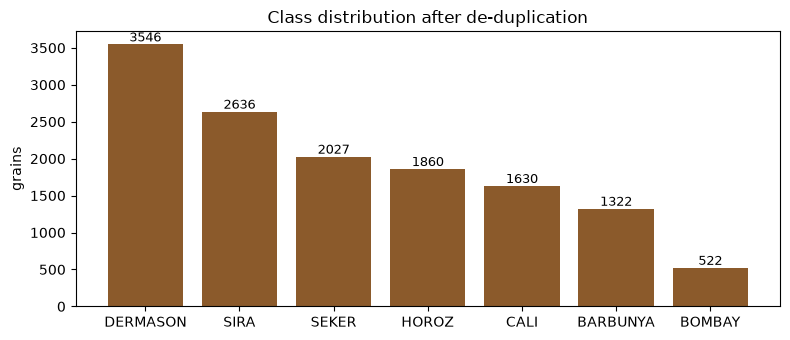

{'DERMASON': 0.262, 'SIRA': 0.195, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.12, 'BARBUNYA': 0.098, 'BOMBAY': 0.039}


In [5]:
# how imbalanced are the classes?
counts = df[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values, color="#8B5A2B")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, str(v), ha="center", fontsize=9)
ax.set_title("Class distribution after de-duplication")
ax.set_ylabel("grains")
plt.tight_layout(); plt.show()
print((counts / counts.sum()).round(3).to_dict())

Clearly imbalanced: DERMASON is ~26% of the data and BOMBAY under 4%. That's why the split is stratified,
the CV objective is **macro**-F1, and the README reports macro-averaged precision/recall/F1.

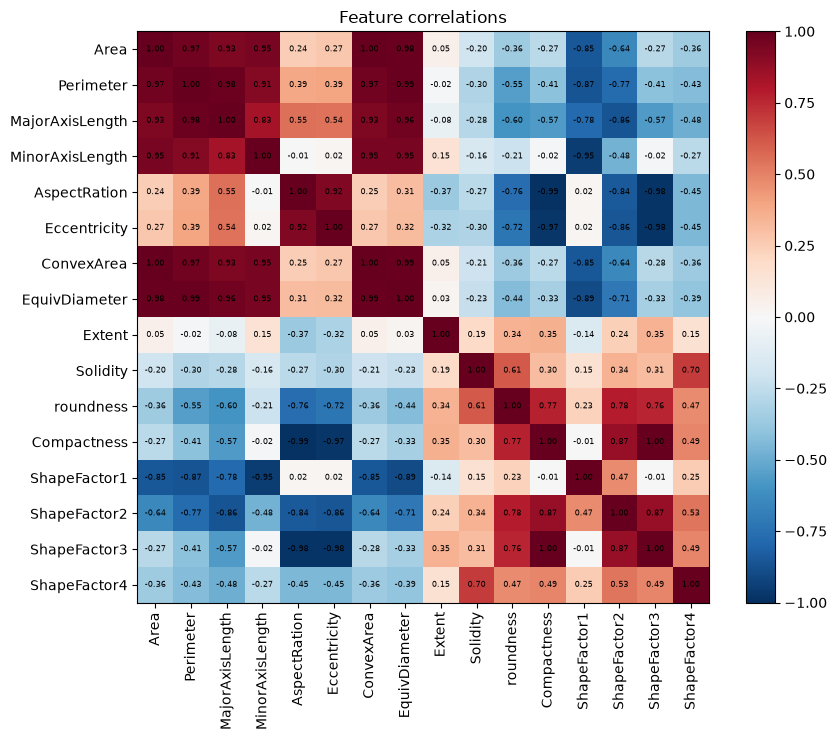

,feature 1,feature 2,r
0,Area,ConvexArea,0.9999
9,Compactness,ShapeFactor3,0.9987
3,Perimeter,EquivDiameter,0.9915
4,AspectRation,Compactness,-0.9876
8,ConvexArea,EquivDiameter,0.9853
1,Area,EquivDiameter,0.9850
7,Eccentricity,ShapeFactor3,-0.9811
5,AspectRation,ShapeFactor3,-0.9785
2,Perimeter,MajorAxisLength,0.9776
6,Eccentricity,Compactness,-0.9703


In [6]:
# Pearson correlation between every pair of features
corr = df[FEATURES].corr().to_numpy()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Feature correlations")
plt.tight_layout(); plt.show()

# list the near-duplicate pairs (|r| > 0.97)
strong = [(a, b, round(df[a].corr(df[b]), 4)) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:]
          if abs(df[a].corr(df[b])) > 0.97]
pd.DataFrame(strong, columns=["feature 1", "feature 2", "r"]).sort_values("r", key=abs, ascending=False)

Lots of near-duplicate information: `Area` vs `ConvexArea` has r ≈ 0.9999, and `Compactness` vs
`ShapeFactor3` ≈ 0.999. That matters for a few models: Naive Bayes assumes features are independent given
the class (they very much aren't here), and QDA/LDA have to invert covariance matrices that are close to
singular, so they get a bit of shrinkage.

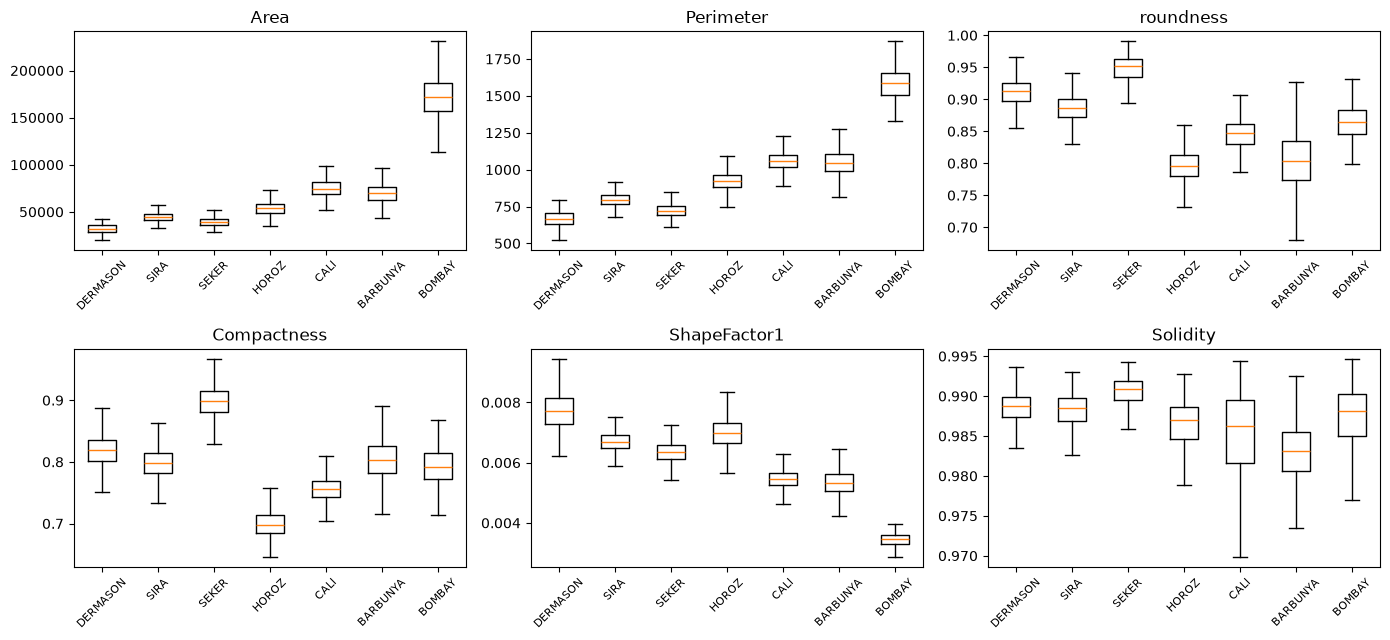

In [7]:
# a few features split by class - shows BOMBAY standing apart and SIRA/DERMASON overlapping
show = ["Area", "Perimeter", "roundness", "Compactness", "ShapeFactor1", "Solidity"]
order = counts.index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, f in zip(axes.ravel(), show):
    ax.boxplot([df.loc[df[TARGET] == c, f] for c in order], showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=45, fontsize=8)
    ax.set_title(f)
plt.tight_layout(); plt.show()

BOMBAY is in a league of its own on size (`Area`, `Perimeter`) — it should be trivially separable.
SIRA and DERMASON sit right next to each other on almost every feature, so that pair is where we expect most
of the confusion. Several features are also quite skewed (`Area` skew ≈ 2.95), which is one more reason the
distance/gradient-based models are trained on standardised features (the scaler is fit on the training
split only and saved inside each model's pipeline).

## 2. Training and tuning

What `run()` does:
1. de-duplicate, label-encode, **stratified 80/20 split** with seed 5327 (from my student id);
   the 20% hold-out is written to `test_data.csv` — that's the file the Streamlit app uses;
2. for each model, a grid search with **stratified k-fold CV on the training 80% only**
   (5 folds, 3 for the kernel SVM), scored by macro-F1;
3. refit the best config on the whole training split and pickle it into `model/` as a
   `Pipeline(scaler, model)`;
4. reload every pickle from disk, re-read `test_data.csv` and compute the metrics — the same path the app
   takes, so the numbers here, in the README and in the app are identical.

Random Forest, AdaBoost, Gradient Boosting and the Perceptron use fixed, sensible hyper-parameters
(GB uses early stopping on an inner validation slice instead). The test set is never used to pick anything.

In [8]:
# the whole pipeline: split -> CV tuning -> final fit -> pickle -> score the test set
t0 = time.time()
results = run(quick=QUICK, seed=SEED)
print(f"\nwhole run took {time.time() - t0:.1f}s")

data: {'rows_raw': 13611, 'exact_duplicates_dropped': 68, 'conflicting_rows_dropped': 0, 'rows_clean': 13543}
train 10836 rows / test 2707 rows -> test_data.csv

[Logistic Regression]


    {'lr': 0.01, 'l2': 0.0} -> macro-F1 0.9352 ± 0.0023


    {'lr': 0.01, 'l2': 0.0001} -> macro-F1 0.9355 ± 0.0023


    {'lr': 0.01, 'l2': 0.001} -> macro-F1 0.9353 ± 0.0018


    {'lr': 0.01, 'l2': 0.01} -> macro-F1 0.9302 ± 0.0044


    {'lr': 0.1, 'l2': 0.0} -> macro-F1 0.9357 ± 0.0028


... (53 outputs left out)

    {'hidden': (128, 64), 'l2': 0.0001} -> macro-F1 0.9413 ± 0.0022


    {'hidden': (128, 64), 'l2': 0.001} -> macro-F1 0.9414 ± 0.0031
  best {'hidden': (128, 64), 'l2': 0.001}  cv macro-F1 0.9414  (13.0s)


  final fit 1.0s



Required models
ML Model Name                Accuracy        AUC  Precision     Recall         F1        MCC
--------------------------------------------------------------------------------------------
Logistic Regression            0.9250     0.9944     0.9359     0.9355     0.9356     0.9093
Decision Tree                  0.8969     0.9777     0.9069     0.9056     0.9059     0.8755
KNN                            0.9224     0.9927     0.9377     0.9321     0.9347     0.9061
Naive Bayes                    0.8977     0.9907     0.9073     0.9053     0.9058     0.8765
Support Vector Machine         0.9346     0.9898     0.9457     0.9430     0.9443     0.9209

Extra models
ML Model Name                Accuracy        AUC  Precision     Recall         F1        MCC
--------------------------------------------------------------------------------------------
Linear SVM                     0.9128     0.9894     0.9257     0.9218     0.9237     0.8945
Averaged Perceptron            0.9261  

## 3. Results on the held-out test set

In [9]:
# turn the saved test metrics into the comparison tables
cols = [("accuracy", "Accuracy"), ("auc", "AUC"), ("precision", "Precision"),
        ("recall", "Recall"), ("f1", "F1"), ("mcc", "MCC")]
rows = [{"ML Model Name": r["name"], "required": r["required"], **{lbl: r["metrics"][k] for k, lbl in cols}}
        for r in results["test"]["models"].values()]
table = pd.DataFrame(rows)
required = table[table.required].drop(columns="required").set_index("ML Model Name")
extras = table[~table.required].drop(columns="required").set_index("ML Model Name")
print("Required models (macro averages, AUC = macro one-vs-rest)")
required.round(4)

Required models (macro averages, AUC = macro one-vs-rest)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9250,0.9944,0.9359,0.9355,0.9356,0.9093
Decision Tree,0.8969,0.9777,0.9069,0.9056,0.9059,0.8755
KNN,0.9224,0.9927,0.9377,0.9321,0.9347,0.9061
Naive Bayes,0.8977,0.9907,0.9073,0.9053,0.9058,0.8765
Support Vector Machine,0.9346,0.9898,0.9457,0.9430,0.9443,0.9209


In [10]:
print("Extra models")
extras.round(4)

Extra models


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Linear SVM,0.9128,0.9894,0.9257,0.9218,0.9237,0.8945
Averaged Perceptron,0.9261,0.9263,0.9355,0.9374,0.9363,0.9107
LDA,0.9040,0.9919,0.9294,0.9129,0.9183,0.8855
QDA,0.9213,0.9920,0.9323,0.9337,0.9329,0.9049
Random Forest,0.9235,0.9936,0.9358,0.9307,0.9331,0.9075
AdaBoost (SAMME),0.8921,0.9800,0.9079,0.9065,0.9057,0.8703
Gradient Boosting,0.9291,0.9944,0.9408,0.9350,0.9378,0.9142
MLP Neural Net,0.9313,0.9954,0.9427,0.9405,0.9414,0.9169
Soft Voting Ensemble,0.9339,0.9955,0.9465,0.9431,0.9447,0.9200


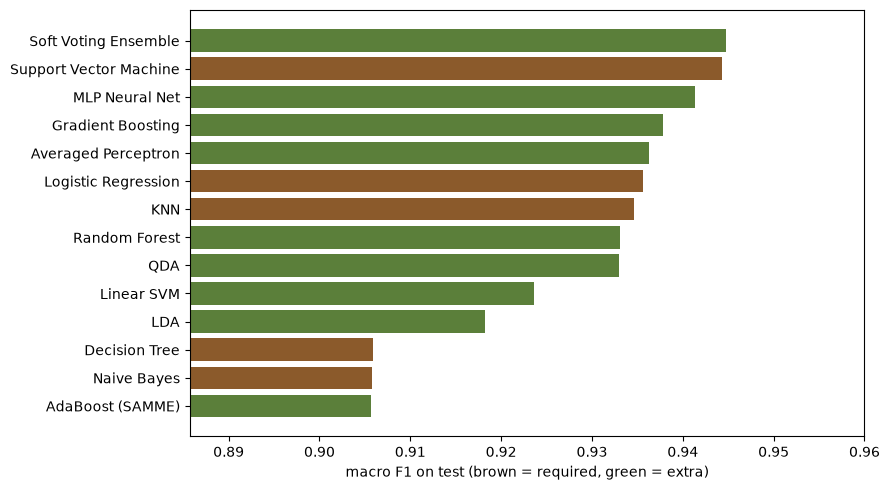

In [11]:
# all 14 models ranked by macro F1
everything = table.drop(columns="required").set_index("ML Model Name").sort_values(["F1", "MCC"], ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
colours = ["#8B5A2B" if table.set_index("ML Model Name").loc[m, "required"] else "#5B7F3A" for m in everything.index]
ax.barh(everything.index[::-1], everything["F1"][::-1], color=colours[::-1])
ax.set_xlim(everything["F1"].min() - 0.02, 0.96)
ax.set_xlabel("macro F1 on test (brown = required, green = extra)")
plt.tight_layout(); plt.show()

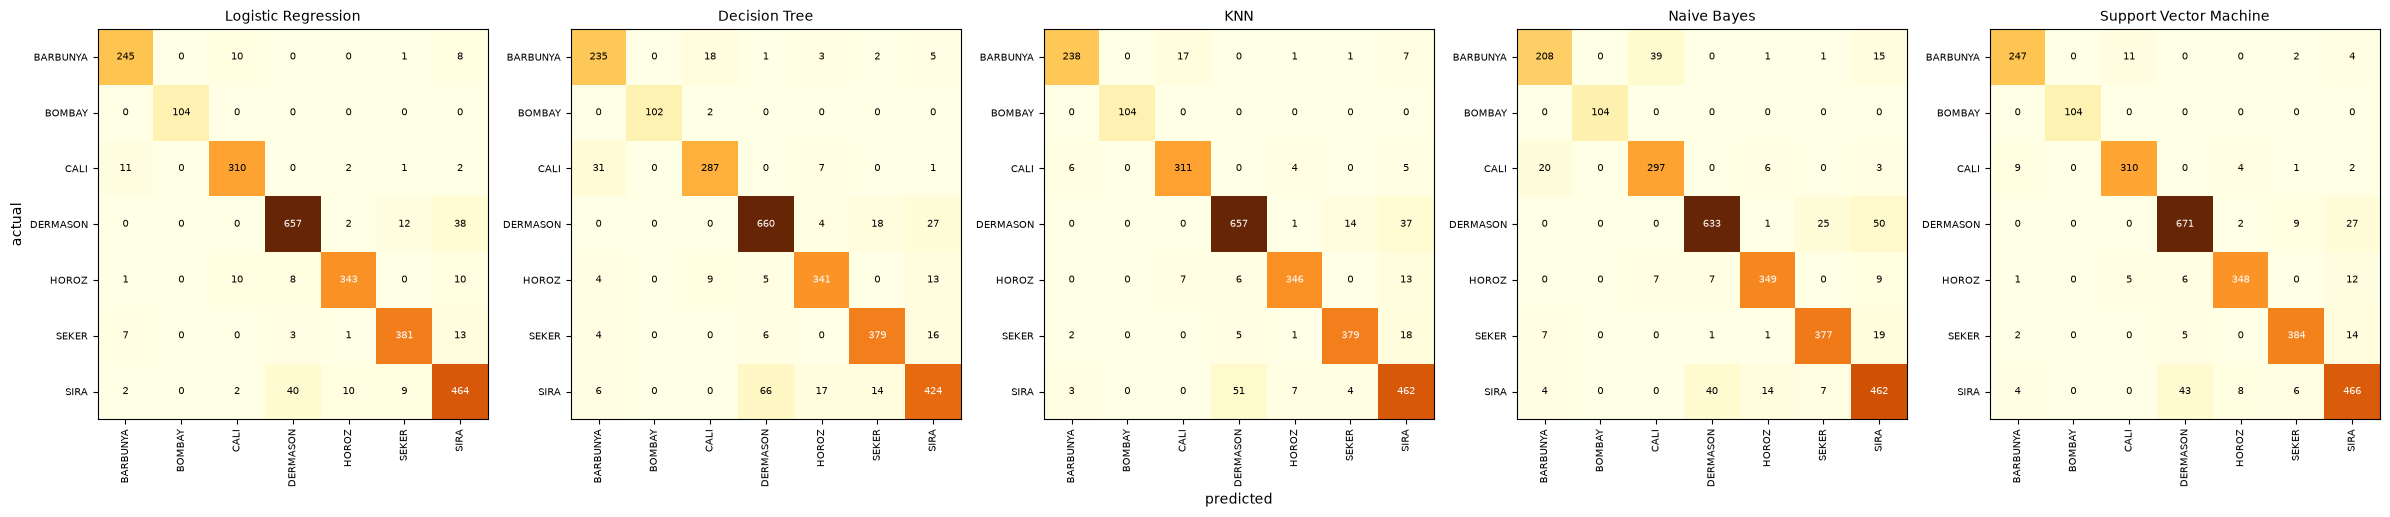

In [12]:
# confusion matrices for the 5 required models (rows = actual, columns = predicted)
names = results["test"]["class_names"]
req_slugs = [s for s, r in results["test"]["models"].items() if r["required"]]
fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, slug in zip(axes, req_slugs):
    cm = np.array(results["test"]["models"][slug]["confusion_matrix"])
    ax.imshow(cm, cmap="YlOrBr")
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
    ax.set_yticks(range(len(names)), names, fontsize=7)
    ax.set_title(results["test"]["models"][slug]["name"], fontsize=10)
axes[0].set_ylabel("actual"); axes[2].set_xlabel("predicted")
plt.tight_layout(); plt.show()

In [13]:
# per-class recall = diagonal / row total, shows which beans each model struggles with
rec = {}
for slug in req_slugs:
    cm = np.array(results["test"]["models"][slug]["confusion_matrix"])
    rec[results["test"]["models"][slug]["name"]] = np.diag(cm) / cm.sum(axis=1)
pd.DataFrame(rec, index=names).T.round(3)

,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Logistic Regression,0.928,1.000,0.951,0.927,0.922,0.941,0.880
Decision Tree,0.890,0.981,0.880,0.931,0.917,0.936,0.805
KNN,0.902,1.000,0.954,0.927,0.930,0.936,0.877
Naive Bayes,0.788,1.000,0.911,0.893,0.938,0.931,0.877
Support Vector Machine,0.936,1.000,0.951,0.946,0.935,0.948,0.884


In [14]:
# top 3 off-diagonal cells = the most common mistakes
for slug in req_slugs:
    cm = np.array(results["test"]["models"][slug]["confusion_matrix"])
    off = sorted(((cm[i, j], names[i], names[j]) for i in range(len(names)) for j in range(len(names)) if i != j),
                 reverse=True)[:3]
    print(f"{results['test']['models'][slug]['name']:24s}", ", ".join(f"{a}->{p}: {n}" for n, a, p in off))

Logistic Regression      SIRA->DERMASON: 40, DERMASON->SIRA: 38, SEKER->SIRA: 13
Decision Tree            SIRA->DERMASON: 66, CALI->BARBUNYA: 31, DERMASON->SIRA: 27
KNN                      SIRA->DERMASON: 51, DERMASON->SIRA: 37, SEKER->SIRA: 18
Naive Bayes              DERMASON->SIRA: 50, SIRA->DERMASON: 40, BARBUNYA->CALI: 39
Support Vector Machine   SIRA->DERMASON: 43, DERMASON->SIRA: 27, SEKER->SIRA: 14


In [15]:
# best hyper-parameters found by cross-validation (training split only)
cv_rows = [{"model": results["test"]["models"][s]["name"], "folds": r["folds"], "best params": r["best"]["params"],
            "CV macro-F1": round(r["best"]["f1_mean"], 4), "± std": round(r["best"]["f1_std"], 4)}
           for s, r in results["cv"].items()]
pd.DataFrame(cv_rows)

,model,folds,best params,CV macro-F1,± std
0,Logistic Regression,5,"{'lr': 0.1, 'l2': 0.0}",0.9357,0.0028
1,Decision Tree,5,"{'criterion': 'entropy', 'max_depth': 10, 'min...",0.9186,0.0026
2,KNN,5,"{'k': 15, 'weights': 'distance', 'metric': 'eu...",0.9367,0.0036
3,Naive Bayes,5,{'var_smoothing': 0.01},0.9059,0.0033
4,Support Vector Machine,3,"{'C': 1000.0, 'gamma': 0.003}",0.9407,0.0032
5,Linear SVM,5,{'C': 1.0},0.9270,0.0040
6,LDA,5,{'shrinkage': 0.0},0.9204,0.0038
7,QDA,5,{'reg_param': 0.01},0.9325,0.0042
8,MLP Neural Net,5,"{'hidden': (128, 64), 'l2': 0.001}",0.9414,0.0031


## 4. Observations

See the README (section d) for the per-model write-up — it's the same text, based on the numbers above.

## 5. Proof of execution environment

In [16]:
# printed for the BITS Virtual Lab screenshot
print("host      :", platform.node())
print("user      :", getpass.getuser())
print("platform  :", platform.platform())
print("python    :", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("finished  :", datetime.datetime.now().isoformat(timespec="seconds"))
print()
print(required.round(4).to_string())

host      : WM-H4PWCTX7G6
user      : anubhav1
platform  : macOS-26.7.1-arm64-arm-64bit
python    : 3.12.13 | numpy 2.5.4 | pandas 3.1.1
finished  : 2026-11-06T11:29:02

                        Accuracy     AUC  Precision  Recall      F1     MCC
ML Model Name                                                              
Logistic Regression       0.9250  0.9944     0.9359  0.9355  0.9356  0.9093
Decision Tree             0.8969  0.9777     0.9069  0.9056  0.9059  0.8755
KNN                       0.9224  0.9927     0.9377  0.9321  0.9347  0.9061
Naive Bayes               0.8977  0.9907     0.9073  0.9053  0.9058  0.8765
Support Vector Machine    0.9346  0.9898     0.9457  0.9430  0.9443  0.9209
